# Dynesty results — visualization

`run_dynesty.py` writes one pickle per insolation model; `load_fits` reads them back as the `{model: NestedFit}` dict every plotting helper takes. Each fit carries **its own data, priors, injected truth and `FittingConfig`**, so nothing has to be re-typed here — `logl_from_fit` rebuilds the exact likelihood the sampler used (needed by 1.–2. and by the posterior predictive, which still evaluate the forward model).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from dynesty_utils import *
from dynesty import utils as dyfunc, plotting as dyplot
from dataclasses import replace
import glob, os

N_JOBS = -1      # forward models run process-parallel (loky); the plots below are the only likelihood cost
INSOL_REF = "hyperillum"   # the model the data were drawn from: always fitted, so it is the reference for the shared (A_B, offset) box and the denominator-free side of every Bayes factor
COLOR  = {"naive": "C0", "hyperillum": "C3", "naive_redist": "C2"}

In [2]:
# --- load data file ---------------------------------------------------------------------------------------
# the DATASET tag: one pattern matching EVERY model of one run, whatever each was sampled with
# (the file names end in _{insolation_model}_priors-..., so this prefix does not fix the free parameters)
results_files = [
    # K2 141b
    "K2-141b_MIRI-LRS_fixedA0.1_AB0.42_nbins27_norbits3_rms1min154.5_sigmascale1_seed42",
    "K2-141b_JWST_NIRSpec.G395H_NRS1_fixedA0.1_AB0.42_nbins27_norbits3_rms1min51.7_sigmascale1_seed42",
    "K2-141b_MIRI-LRS_fixedA0.1_AB0.1_nbins27_norbits3_rms1min154.5_sigmascale1_seed42",
    "K2-141b_MIRI-LRS_fixedA0.1_AB0.42_nbins27_norbits3_rms1min154.5_sigmascale0.1_seed42",
    "K2-141b_MIRI-LRS_fixedA0.1_AB0.42_nbins27_norbits3_rms1min154.5_sigmascale0.5_seed42",
    "K2-141b_MIRI-LRS_scaledA1_AB0.42_nbins27_norbits3_rms1min154.5_sigmascale1_seed42",
    # TOI 2431b
    "TOI-2431b_JWST_NIRSpec.G395H_NRS1_fixedA0.1_AB0.42_nbins27_norbits3_rms1min38.3_sigmascale1_seed43",
    "TOI-2431b_JWST_NIRSpec.G395H_NRS1_fixedA0.1_AB0.42_nbins27_norbits3_rms1min38.3_sigmascale1_seed42",
    "TOI-2431b_JWST_NIRSpec.G395H_NRS1_fixedA0.1_AB0.42_nbins27_norbits3_rms1min38.3_sigmascale1_seed41",
    "TOI-2431b_JWST_NIRSpec.G395H_NRS1_fixedA0.1_AB0.42_nbins27_norbits3_rms1min38.3_sigmascale1_seed40",
    "TOI-2431b_MIRI-F1280W_fixedA0.1_AB0.42_nbins27_norbits3_rms1min247.2_sigmascale1_seed42",
    "TOI-2431b_MIRI-LRS_fixedA0.1_AB0.42_nbins27_norbits3_rms1min91.9_sigmascale0.1_seed42",
    "TOI-2431b_MIRI-LRS_fixedA0.1_AB0.42_nbins27_norbits3_rms1min91.9_sigmascale0.5_seed42",
    "TOI-2431b_MIRI-LRS_fixedA0.1_AB0.42_nbins27_norbits3_rms1min91.9_sigmascale1_seed42",
    # K2-157b
    "K2-157b_MIRI-LRS_fixedA0.1_AB0.42_nbins27_norbits3_rms1min1102.9_sigmascale1_seed42",
    # KOI-1843.03
    "KOI-1843.03_MIRI-LRS_fixedA0.1_AB0.42_nbins27_norbits3_rms1min868.8_sigmascale1_seed42",
    # TOI-2260b
    "TOI-2260b_MIRI-LRS_fixedA0.1_AB0.42_nbins27_norbits3_rms1min182.0_sigmascale1_seed42",
]

results_file = "TOI-2431b_JWST_NIRSpec.G395H_NRS1_fixedA0.1_AB0.42_nbins27_norbits3_rms1min38.3_sigmascale1_seed42"

RESULTS = f"more runs/OLD_before_midpoint_binning/dynesty_results/{results_file}_*.pkl"

In [3]:
fits  = load_fits(RESULTS)                                    # {insolation_model: NestedFit}; whichever models the pattern found
fits  = {m: fits[m] for m in ("hyperillum", "naive", "naive_redist") if m in fits}   # fixed order, so colours and panels do not depend on how the files happened to sort
logls = {m: logl_from_fit(f) for m, f in fits.items()}        # the likelihood each fit was run with, rebuilt from its own cfg

# The models need NOT share a ParameterSet: only "naive_redist" samples F. Everything shared comes from the truth's own model, which is always run.
ref   = fits[INSOL_REF]
pset  = ref.pset                                               # the (A_B, offset) box every model has - what the grids below are built on
PSETS = {m: f.pset for m, f in fits.items()}                   # what each model was ACTUALLY sampled with
cfg   = ref.meta["cfg"]
data  = ref.meta["data"]
truth = data["truth"]                                          # what simulate_data injected
A_B_true, INSOL_TRUTH = truth["A_B"], truth["insolation_model"]
assert INSOL_TRUTH == INSOL_REF, f"the data were drawn from {INSOL_TRUTH}, but INSOL_REF is {INSOL_REF}"
# the injected value of every parameter ANY model samples. The data are drawn without redistribution, so F = 0 is the truth for it too.
TRUTH_OF = dict(A_B=A_B_true, offset=truth["offset"], F=0.)
base  = {n: TRUTH_OF[n] for f in fits.values() for n in f.pset.names}

print(f"{cfg.planet.name}   truth = {INSOL_TRUTH}, A_B = {A_B_true:g}, offset = {truth['offset']:g} ppm, data seed = {truth['seed']}")
print(f"{cfg.n_bins} bins over {cfg.n_orbits} orbits, rms_1min_pandexo = {cfg.sigma_1min:.1f} ppm -> sigma_bin = {cfg.sigma_bin:.1f} ppm   |   models: {', '.join(fits)}\n")
print(f"{'model':12s} {'lnZ':>20s} {'ncall':>8s} {'runtime':>9s}   status   (ESS is part of the status line)")
for m, f in fits.items():
    print(f"{m:12s} {f.meta['lnZ']:10.4f} +/- {f.meta['lnZ_err']:.4f} {f.meta['ncall']:8d} {f.meta['runtime_s']/60:7.1f} m   {f.meta['status']}")
    print(f"{'':12s} sampled: {', '.join(f.pset.names)}")
    print(f"{'':12s} {os.path.basename(f.meta.get('file', '(not saved)'))}")

TOI-2431 b   truth = hyperillum, A_B = 0.42, offset = 0 ppm, data seed = 42
27 bins over 3 orbits, rms_1min_pandexo = 38.3 ppm -> sigma_bin = 6.4 ppm   |   models: hyperillum, naive

model                         lnZ    ncall   runtime   status   (ESS is part of the status line)
hyperillum     -88.6842 +/- 0.0570    32205     5.0 m   CONVERGED | stop 0.990, 9/10 batches, ESS 9132
             sampled: A_B, offset
             TOI-2431b_JWST_NIRSpec.G395H_NRS1_fixedA0.1_AB0.42_nbins27_norbits3_rms1min38.3_sigmascale1_seed42_hyperillum_priors-A_B+offset.pkl
naive          -87.8959 +/- 0.0561    31673     8.8 m   CONVERGED | stop 0.997, 9/10 batches, ESS 9037
             sampled: A_B, offset
             TOI-2431b_JWST_NIRSpec.G395H_NRS1_fixedA0.1_AB0.42_nbins27_norbits3_rms1min38.3_sigmascale1_seed42_naive_priors-A_B+offset.pkl


## 1. Data and Likelihood

Plotted as $\Delta\ln\mathcal{L}=\ln\mathcal{L}-\ln\mathcal{L}_{\max}$. In the slices the dotted lines at $-0.5,-2,-4.5$ are the 1-parameter $1/2/3\sigma$ levels; in the map the contours are the 2-parameter ones ($-1.15,-3.09,-5.91$). With uniform priors $\exp(\ln\mathcal{L})$ over this box *is* the un-normalised posterior, so the map previews the corner plot in 2.

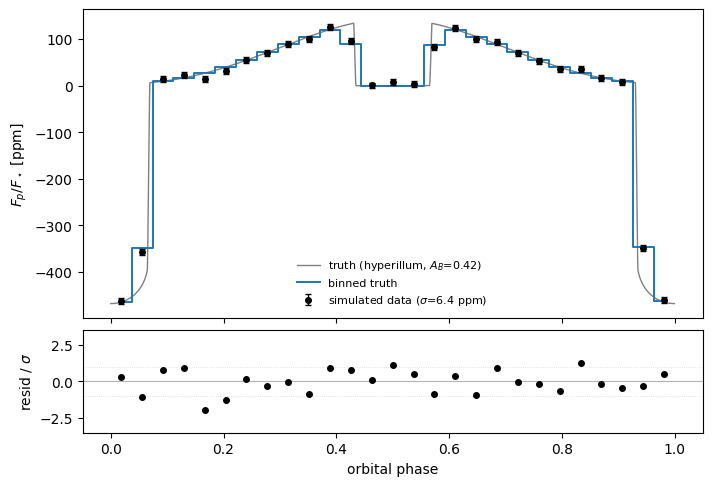

sigma_bin: 6.39 ppm  (bin width 11.96 min)
chi2 / n_bins (normalized average noise per bin ~1): 0.63
residual mean / sigma (~0): -0.03


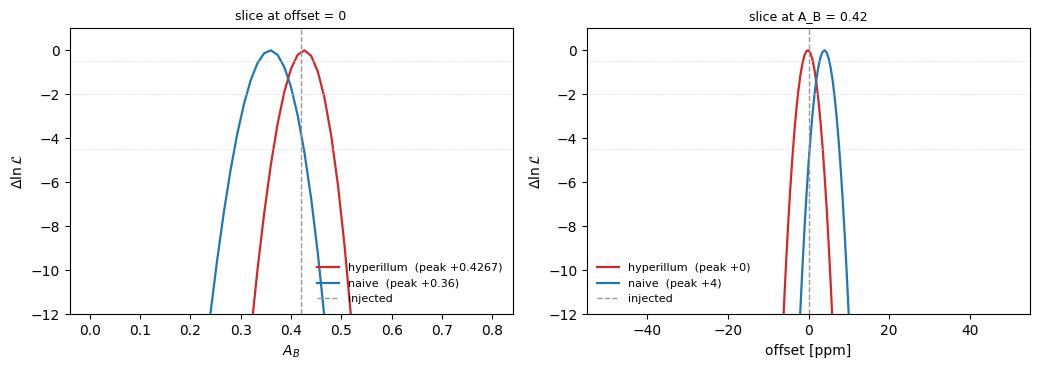

hyperillum   grid MAP: A_B = 0.4267, offset = +0.00 ppm, lnL = -83.013
naive        grid MAP: A_B = 0.4000, offset = +3.00 ppm, lnL = -82.313


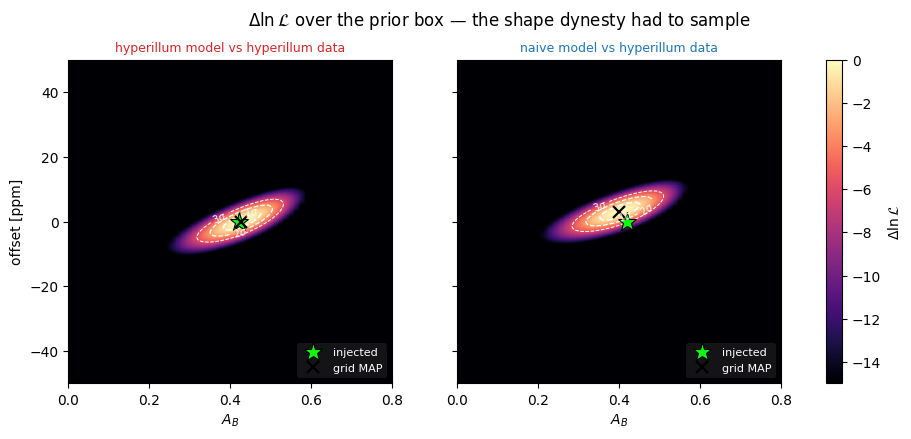

In [4]:
A_grid, O_grid = pset.grid("A_B", 61),  pset.grid("offset", 201)

# the truth curve is re-evaluated here (one forward model), the data points come straight out of the saved fit
plot_simulated_data(cfg, A_B_true, data, insolation_model=INSOL_TRUTH)

# 1D slices. One panel per parameter ANY model samples - so F gets its own as soon as a "naive_redist" run is loaded,
# and the models that do not sample it simply have no curve there.
F_MODELS = [m for m in fits if "F" in PSETS[m].names]          # [] when no redistribution run is in this dataset
GRIDS  = {"A_B": A_grid, "offset": O_grid}
if F_MODELS: GRIDS["F"] = PSETS[F_MODELS[0]].grid("F", 61)     # the full [0, 0.5] prior; the panel is zoomed below
XLABEL = {"A_B": "$A_B$", "offset": "offset [ppm]", "F": "$F$ (heat redistribution)"}
YLIM   = -12.

SLICES = {}
fig, axes = plt.subplots(1, len(GRIDS), figsize=(5.25 * len(GRIDS), 3.8), squeeze=False)
for ax, (p, g) in zip(axes.ravel(), GRIDS.items()):
    for name, L in logls.items():
        if p not in L.names: continue                          # e.g. F, which only "naive_redist" has
        s = logl_slice(L, p, g, base, n_jobs=N_JOBS)           # one forward model per node, except "offset" (additive -> free)
        SLICES[p, name] = s
        # dashed for naive_redist: at the injected F = 0 it IS the naive model, so in the A_B and offset panels the two curves lie exactly on top of each other
        ax.plot(g, s - s.max(), color=COLOR[name], lw=1.6, ls="--" if name == "naive_redist" else "-", label=f"{name}  (peak {g[s.argmax()]:+.4g})")
    for d in (-0.5, -2.0, -4.5):
        ax.axhline(d, color="0.85", lw=0.7, ls=":")
    ax.axvline(base[p], color="0.6", lw=1.0, ls="--", label="injected")
    ax.set_xlabel(XLABEL[p]); ax.set_ylabel(r"$\Delta\ln\mathcal{L}$")
    ax.set_ylim(YLIM, 1.); ax.legend(frameon=False, fontsize=8)
    ax.set_title("slice at " + ", ".join(f"{q} = {base[q]:g}" for q in GRIDS if q != p), fontsize=9)
    if p == "F":   # the F posterior is a sliver against its [0, 0.5] prior, so zoom the axis to where the curve is still on the panel (linear, never sqrt)
        on = np.concatenate([g[(SLICES[p, m] - SLICES[p, m].max()) > YLIM] for m in F_MODELS])
        F_LIM = (max(g[0], on.min() - 0.1 * np.ptp(on) - 1e-3), min(g[-1], on.max() + 0.5 * np.ptp(on) + 1e-3))   # numpy 2: np.ptp, not ndarray.ptp   # reused by the (A_B, F) map below
        ax.set_xlim(*F_LIM)
plt.tight_layout(); plt.show()

# 2D map
lnL_maps = {}
for name, L in logls.items():
    lnL = logl_grid(L, "A_B", A_grid, "offset", O_grid, base, n_jobs=N_JOBS)   # (n_off, n_A_B)
    lnLmax, (off_map, A_map) = grid_max(lnL, O_grid, A_grid)                   # axis order of lnL: (offset, A_B)
    lnL_maps[name] = (lnL, lnLmax, A_map, off_map)
    print(f"{name:12s} grid MAP: A_B = {A_map:.4f}, offset = {off_map:+.2f} ppm, lnL = {lnLmax:.3f}")

fig, axes = plt.subplots(1, len(lnL_maps), figsize=(5.75 * len(lnL_maps), 4.2), sharex=True, sharey=True, squeeze=False)
axes = axes.ravel()
for ax, (name, (lnL, lnLmax, A_map, off_map)) in zip(axes, lnL_maps.items()):
    d = lnL - lnLmax
    im = ax.pcolormesh(A_grid, O_grid, d, vmin=-15, vmax=0., cmap="magma", shading="gouraud")
    cs = ax.contour(A_grid, O_grid, d, levels=[-5.91, -3.09, -1.15], colors="w", linewidths=[0.7, 0.9, 1.2])
    ax.clabel(cs, fmt={-5.91: r"3$\sigma$", -3.09: r"2$\sigma$", -1.15: r"1$\sigma$"}, fontsize=7)
    ax.plot(A_B_true, base["offset"], "*", ms=14, mfc="#0cff0c", mec="k", mew=.8, label="injected")   # not C0/C3: those now mean naive/hyperillum
    ax.plot(A_map, off_map, "x", ms=9, color="k", mew=1.6, label="grid MAP")   # the MAP always sits in the bright peak
    ax.set_xlabel("$A_B$")
    ax.set_title(f"{name} model vs {INSOL_TRUTH} data", fontsize=9, color=COLOR[name])
    ax.legend(loc="lower right", fontsize=8, labelcolor="w", facecolor="0.15", edgecolor="none", framealpha=.55)
axes[0].set_ylabel("offset [ppm]")
fig.colorbar(im, ax=axes, label=r"$\Delta\ln\mathcal{L}$")   # shared: both panels use vmin=-15, vmax=0
fig.suptitle(r"$\Delta\ln\mathcal{L}$ over the prior box — the shape dynesty had to sample", y=1.0)
plt.show()

# 2D map over (A_B, F), the pair the whole naive_redist fit is about: how much albedo the fit trades for how much
# redistribution. The additive offset is PROFILED OUT rather than held at base (it correlates with F, so a fixed-offset
# slice looks tighter than the fit is) - free, since every offset reuses the cell's one forward model.
lnL_maps_F = {}
if F_MODELS:
    A_gridF = pset.grid("A_B", 41)
    F_gridF = np.linspace(*F_LIM, 31)   # the same zoom as the slice panel, so the two F figures are on one scale
    for name in F_MODELS:
        lnL = logl_grid(logls[name], "A_B", A_gridF, "F", F_gridF, base, n_jobs=N_JOBS, profile_offset=O_grid)   # (n_F, n_A_B)
        lnLmax, (F_map, A_map) = grid_max(lnL, F_gridF, A_gridF)                                                 # axis order of lnL: (F, A_B)
        lnL_maps_F[name] = (lnL, lnLmax, A_map, F_map)
        print(f"{name:12s} grid MAP: A_B = {A_map:.4f}, F = {F_map:.4f}, lnL = {lnLmax:.3f}   (offset profiled out)")

    fig, axes = plt.subplots(1, len(lnL_maps_F), figsize=(5.75 * len(lnL_maps_F), 4.2), sharex=True, sharey=True, squeeze=False)
    for ax, (name, (lnL, lnLmax, A_map, F_map)) in zip(axes.ravel(), lnL_maps_F.items()):
        d = lnL - lnLmax
        im = ax.pcolormesh(A_gridF, F_gridF, d, vmin=-15, vmax=0., cmap="magma", shading="gouraud")
        cs = ax.contour(A_gridF, F_gridF, d, levels=[-5.91, -3.09, -1.15], colors="w", linewidths=[0.7, 0.9, 1.2])
        ax.clabel(cs, fmt={-5.91: r"3$\sigma$", -3.09: r"2$\sigma$", -1.15: r"1$\sigma$"}, fontsize=7)
        ax.plot(A_B_true, base["F"], "*", ms=14, mfc="#0cff0c", mec="k", mew=.8, label="injected ($F=0$)")
        ax.plot(A_map, F_map, "x", ms=9, color="k", mew=1.6, label="grid MAP")
        ax.set_xlabel("$A_B$")
        ax.set_title(f"{name} model vs {INSOL_TRUTH} data", fontsize=9, color=COLOR[name])
        ax.legend(loc="upper right", fontsize=8, labelcolor="w", facecolor="0.15", edgecolor="none", framealpha=.55)
    axes.ravel()[0].set_ylabel("$F$")
    fig.colorbar(im, ax=axes, label=r"$\Delta\ln\mathcal{L}$")
    fig.suptitle(r"$\Delta\ln\mathcal{L}$ over $(A_B, F)$, offset profiled out — the albedo-redistribution degeneracy", y=1.0)
    plt.show()

## 2. Dynesty results

Posterior overlay (filled: the sampler's 68/95% credible regions from `samples_equal()`; dotted: the profile-likelihood contours from 1.), the per-parameter bias against the injected truth, and the Bayes factor. The one-seed fits against the noiseless truth are in 4.

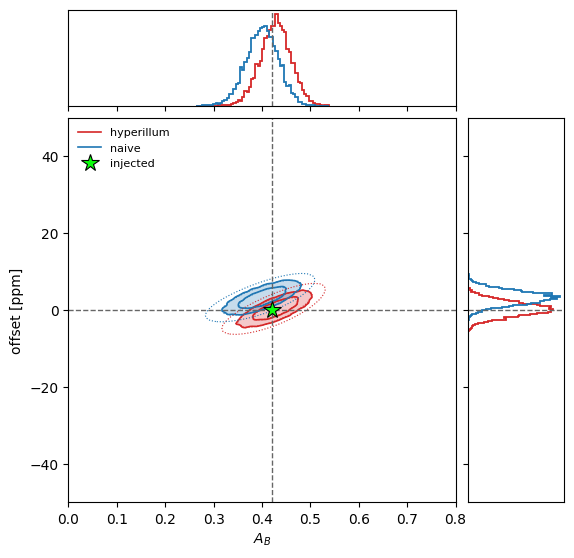

hyperillum   ESS 9132, information 4.70 nats
   A_B      =    0.4290 +0.0297 -0.0313   truth 0.42, bias +0.0090 = +0.29 sigma
   offset   =    0.2474 +1.9264 -1.9088   truth 0, bias +0.2474 = +0.13 sigma
   corr(A_B, offset) = +0.772
naive   ESS 9037, information 4.59 nats
   A_B      =    0.4013 +0.0323 -0.0334   truth 0.42, bias -0.0187 = -0.57 sigma
   offset   =    3.1966 +1.8280 -1.8247   truth 0, bias +3.1966 = +1.75 sigma
   corr(A_B, offset) = +0.740
ln B (hyperillum vs naive) = -0.788 +/- 0.080 (analytic) +/- 0.125 (jitter, K=200)  ->  B = 0.455
P(sign of ln B secure) = 0.000  [sampler noise only, NOT a model probability]


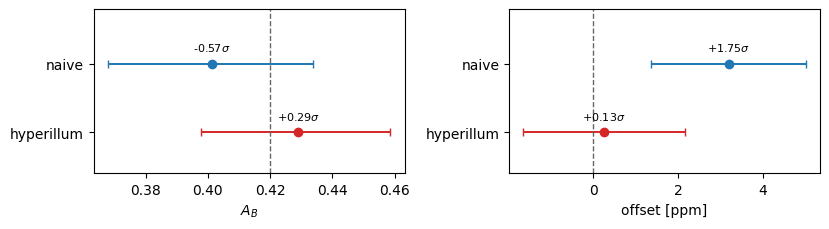

In [5]:
# Posterior
profile = {name: (A_grid, O_grid, lnL) for name, (lnL, *_) in lnL_maps.items()}   # logl_grid returns (offset, A_B), which is what contour(A_grid, O_grid, ...) wants
plot_posterior_overlay(fits, "A_B", "offset", truth=base, profile=profile, colors=COLOR)
plt.show()

# Bayes Factor lnB
for f in fits.values(): posterior_summary(f, base)
# one Bayes factor per alternative present, each against the truth's own model
bfs = {m: bayes_factor(fits, INSOL_REF, m, K=200) for m in fits if m != INSOL_REF}

plot_bias(fits, base, colors=COLOR); plt.show()

# F-specific posteriors, whenever a loaded model samples it
if F_MODELS:
    # the (A_B, F) plane: filled = the sampler's credible regions, dotted = the profile-likelihood contours of the map in 1.
    plot_posterior_overlay({m: fits[m] for m in F_MODELS}, "A_B", "F", truth=base,
                           profile={m: (A_gridF, F_gridF, lnL) for m, (lnL, *_) in lnL_maps_F.items()}, colors=COLOR)
    plt.show()

    # full corner: F against every other sampled parameter, from the equal-weight posterior
    for m in F_MODELS:
        fig, _ = dyplot.cornerplot(fits[m].results, labels=list(PSETS[m].labels), color=COLOR[m],
                                   truths=[base[n] for n in PSETS[m].names], truth_color="0.4",
                                   show_titles=True, title_fmt=".3f", quantiles=(0.16, 0.5, 0.84),
                                   fig=plt.subplots(PSETS[m].ndim, PSETS[m].ndim, figsize=(2.6 * PSETS[m].ndim,) * 2))
        fig.suptitle(f"{m} posterior (injected: " + ", ".join(f"{n} = {base[n]:g}" for n in PSETS[m].names) + ")", y=1.04)
        plt.show()

## 3. Posterior predictive — and where in phase the evidence comes from

Bottom panel (the `num` - `den` pair only; every model is still in the two panels above): the difference of the two median curves against $\pm\sigma_{\rm bin}$, plus the per-bin $\Delta\chi^2$ between the two **best-fit** (max-$\ln\mathcal{L}$) models. Those bars sum to $2\,\Delta\ln\mathcal{L}_{\max}$, so they attribute the evidence to specific orbital phases.

Costs `N_DRAWS` forward models per insolation model.

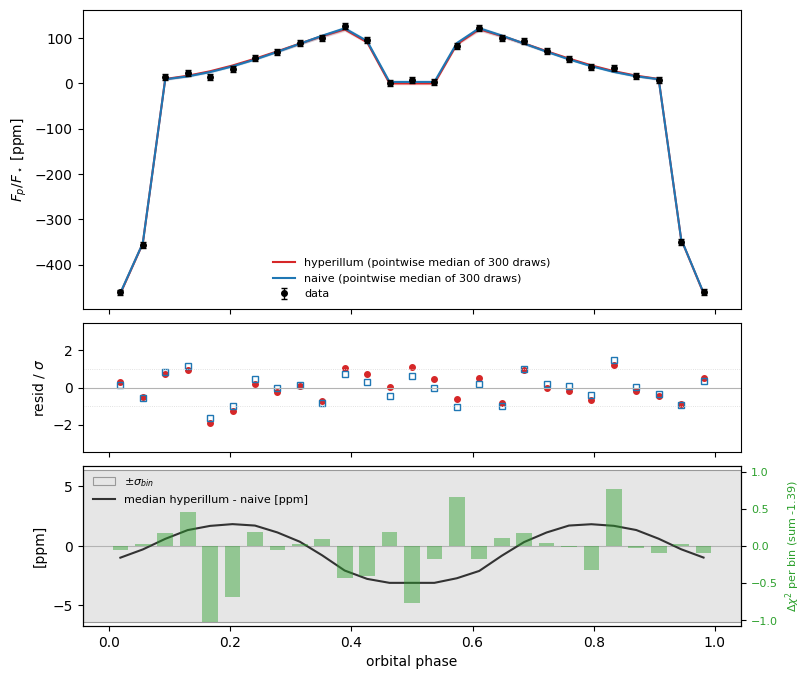

In [6]:
N_DRAWS = 300   # forward models per insolation model

plot_posterior_predictive(logls, fits, n=N_DRAWS, colors=COLOR, n_jobs=N_JOBS)
plt.show() # per-bin Δχ², computed as [(y−best_a)² − (y−best_b)²]/σ², so a bar is positive where model b fits that bin better.

## 4. Bias analysis

NOISELESS naive vs the NOISELESS truth  (offset free, no noise, no seed - this is THE bias):
   A_B      0.3948   bias -0.0252 = -0.77 sigma_A_B   ->   dT/T = +1.07 %
   |dA_B|/sigma_A_B = 0.77   ->   sigma_1min,crit = 29.3 ppm/min   (now 38.3, so 1.3x finer photometry - or 2x the orbits - before the bias reaches 1 sigma)
   bias / floor = 1.870 / 0.634 = 3.0x   ->   NOT RESOLVED - refine model_kw (n_lo, n_la, n_layers, n_t) before quoting any bias from this run


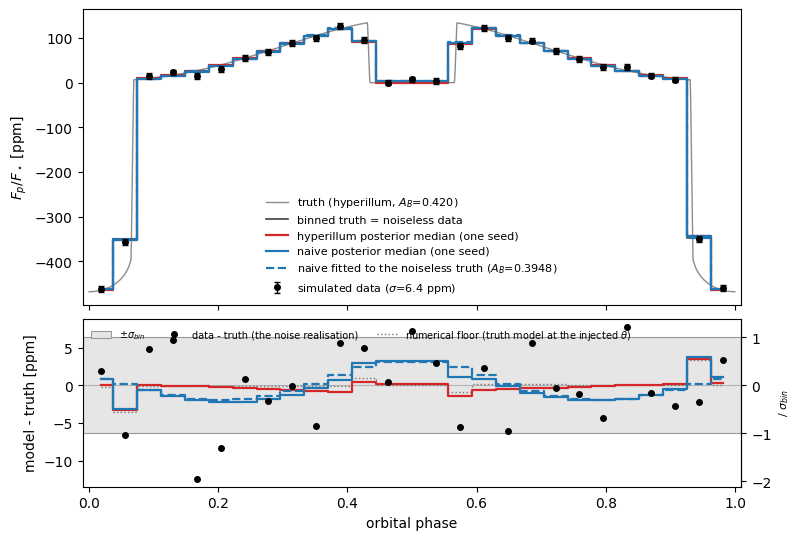

In [7]:
fig, (ax, axr), out = plot_noisy_vs_truth(cfg, data, logls, fits, A_B_true, base, insolation_truth=INSOL_TRUTH,
                                          A_B_bounds=pset.bounds[pset.names.index("A_B")], colors=COLOR)
plt.show()

## 5. Derived quantities

The $A_B$ posterior pushed through to physics, each model through **its own** temperature map - i.e. what you would infer if you believed that model.
`T_term` > 0 for naive is an interpolation artefact: it is `np.interp` of the temperature grid at exactly 90°, between the last dayside and the first nightside node. The naive nightside itself (`T_anti`) is 0 K.

hyperillum   occultation_depth  136.71 ppm
naive        occultation_depth  134.52 ppm
hyperillum   depth  141.7 +4.5 -4.4 ppm (thermal 135.4, reflected 6.3)   T_bright 2193.1 +31.6 -30.7 K
             T_sub 2488.1 K   T_term 1384.7 K   T_anti   0.0 K
naive        depth  143.1 +4.0 -4.0 ppm (thermal 136.9, reflected 6.2)   T_bright 2203.7 +27.5 -28.3 K
             T_sub 2505.2 K   T_term  505.8 K   T_anti   0.0 K


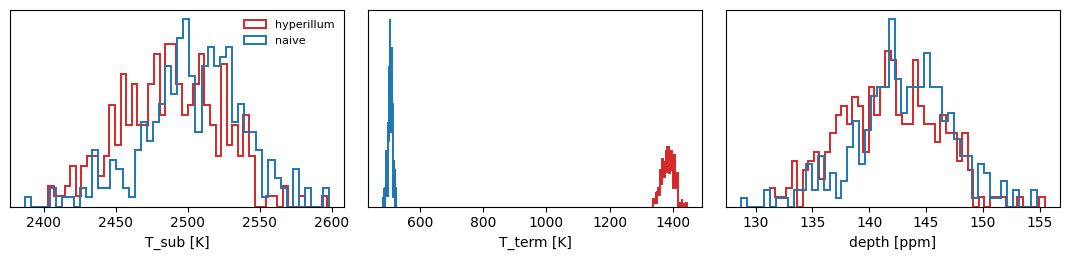

In [8]:
# Check on the factored-out pcurve_params: for a thermal-only, transit-free config the occultation depth must match the peak of the phase curve model_pcurve builds from the same sp.ModelParams.
cfg_th = replace(cfg, reflected=False, transit=False)
for m in fits:
    F_ = base["F"] if "F" in PSETS[m].names else None   # only "naive_redist" has one, and at the injected truth it is 0
    _, y_ = model_pcurve(cfg_th, m, A_B_true, F=F_, n_t=200 * cfg.n_bins)
    d_ = occultation_depth(pcurve_params(cfg_th, m, A_B_true, F=F_), stellar_grid=cfg.stellar_grid)
    print(f"{m:12s} occultation_depth {d_:7.2f} ppm")

der = {m: derived_samples(logls[m], equal_samples(fits[m], N_DRAWS, seed=0), n_jobs=N_JOBS) for m in fits}
for name, d in der.items():
    q, q_th = np.percentile(d["depth"], [16, 50, 84]), np.percentile(d["depth_th"], [16, 50, 84])
    Tb = brightness_temperature(d["depth_th"], cfg)
    print(f"{name:12s} depth {q[1]:6.1f} +{q[2]-q[1]:.1f} -{q[1]-q[0]:.1f} ppm (thermal {q_th[1]:.1f}, reflected {np.median(d['depth_refl']):.1f})   T_bright {Tb[1]:6.1f} +{Tb[2]-Tb[1]:.1f} -{Tb[1]-Tb[0]:.1f} K")
    print(f"{'':12s} T_sub {np.median(d['T_sub']):6.1f} K   T_term {np.median(d['T_term']):6.1f} K   T_anti {np.median(d['T_anti']):5.1f} K")

plot_derived(der, keys=("T_sub", "T_term", "depth"), colors=COLOR); plt.show()